## 1. Introduction
Explain why preprocessing is necessary for text classification.

Text classification algorithms require numerical input. Preprocessing transforms raw, unstructured text into a clean, normalized format that can be effectively converted into meaningful numerical representations (like TF-IDF). It reduces noise (like HTML tags or inconsistent casing) and reduces the vocabulary size, allowing the model to focus on patterns that distinguish spam from legitimate (ham) emails.


## 2. Load the original dataset


In [1]:
import pandas as pd
import numpy as np
import os
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Load original dataset
# Using the path relative to notebooks directory
email_data_path = '../data/raw/enron_spam_data.csv'
try:
    df_email_raw = pd.read_csv(email_data_path)
    print(f'Original email dataset shape: {df_email_raw.shape}')
except FileNotFoundError:
    print(f'File not found: {email_data_path}')


Original email dataset shape: (33716, 5)


## 3. Create a preprocessing copy
We keep the original dataframe untouched and work on a copy to ensure we do not modify the raw data.


In [2]:
if 'df_email_raw' in locals():
    df_email = df_email_raw.copy()


## 4. Remove irrelevant columns
We remove `Unnamed: 0` because it is just a pandas index column saved in the CSV and carries no predictive value.
We remove `Date` because we are building a content-based classifier (text classifier) that should rely on the text of the email, not temporal metadata, to prevent the model from memorizing specific time periods associated with the dataset collection.


In [3]:
if 'df_email' in locals():
    df_email = df_email.drop(columns=['Unnamed: 0', 'Date'], errors='ignore')
    print('Columns after removal:', df_email.columns.tolist())


Columns after removal: ['Subject', 'Message', 'Spam/Ham']


## 5. Handle missing Message values
There are exactly 52 missing Message values. We do not blindly drop these rows because the `Subject` field is still present and useful. We will fill missing `Message` values with an empty string.


In [4]:
if 'df_email' in locals():
    print(f'Missing messages before: {df_email["Message"].isnull().sum()}')
    df_email['Message'] = df_email['Message'].fillna('')


Missing messages before: 52


## 6. Verify missing values again


In [5]:
if 'df_email' in locals():
    print('Missing values after handling:')
    print(df_email.isnull().sum())


Missing values after handling:
Subject     0
Message     0
Spam/Ham    0
dtype: int64


## 7. Combine Subject and Message
We create a new in-memory column `email_text` by combining the Subject and the Message.


In [6]:
if 'df_email' in locals():
    df_email['Subject'] = df_email['Subject'].fillna('')
    df_email['email_text'] = df_email['Subject'] + ' ' + df_email['Message']


## 8. Clean text
The initial preprocessing should convert text to lowercase, normalize whitespace, remove HTML tags, remove URLs, and remove unnecessary punctuation while preserving meaningful word characters. We do not over-clean (e.g., blindly stem or remove stopwords) because certain stopwords (like 'urgent', 'click', 'here') or capitalization/formatting artifacts could be strong spam indicators.


In [7]:
def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    # Convert to lowercase
    text = text.lower()
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remove URLs
    text = re.sub(r'http[s]?://\S+|www\.\S+', ' ', text)
    # Remove unnecessary punctuation but preserve meaningful word characters
    # (replace non-alphanumeric with space)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

if 'df_email' in locals():
    df_email['email_text_clean'] = df_email['email_text'].apply(preprocess_text)


## 9. Display examples


In [8]:
if 'df_email' in locals():
    for i in range(3):
        print(f'--- Example {i+1} ---')
        print(f'Original Subject: {df_email["Subject"].iloc[i]}')
        print(f'Original Message: {df_email["Message"].iloc[i][:150]}...')
        print(f'Processed Text:   {df_email["email_text_clean"].iloc[i][:150]}...\n')


--- Example 1 ---
Original Subject: christmas tree farm pictures
Original Message: ...
Processed Text:   christmas tree farm pictures...

--- Example 2 ---
Original Subject: vastar resources , inc .
Original Message: gary , production from the high island larger block a - 1 # 2 commenced on
saturday at 2 : 00 p . m . at about 6 , 500 gross . carlos expects between ...
Processed Text:   vastar resources inc gary production from the high island larger block a 1 2 commenced on saturday at 2 00 p m at about 6 500 gross carlos expects bet...

--- Example 3 ---
Original Subject: calpine daily gas nomination
Original Message: - calpine daily gas nomination 1 . doc...
Processed Text:   calpine daily gas nomination calpine daily gas nomination 1 doc...



## 10. Label encoding
Convert ham -> 0, spam -> 1


In [9]:
if 'df_email' in locals():
    df_email['y_email'] = df_email['Spam/Ham'].map({'ham': 0, 'spam': 1})
    print('Class distribution after encoding:')
    print(df_email['y_email'].value_counts(normalize=True))


Class distribution after encoding:
y_email
1    0.509283
0    0.490717
Name: proportion, dtype: float64


## 11. Train/test split
We split the data BEFORE fitting the TF-IDF vectorizer to strictly avoid data leakage. If we fit the vectorizer on the entire dataset, the training set vocabulary and document frequencies would be influenced by the test set, giving the model unfair knowledge of the test data.


In [10]:
if 'df_email' in locals():
    X_email = df_email['email_text_clean']
    y_email = df_email['y_email']

    X_email_train, X_email_test, y_email_train, y_email_test = train_test_split(
        X_email, y_email, test_size=0.20, random_state=42, stratify=y_email
    )
    print(f'Train size: {X_email_train.shape[0]}, Test size: {X_email_test.shape[0]}')


Train size: 26972, Test size: 6744


## 12. TF-IDF
- **Term Frequency (TF):** Measures how frequently a term appears in a document.
- **Inverse Document Frequency (IDF):** Reduces the weight of terms that occur very frequently across the entire corpus and increases the weight of rare terms.
- **N-grams (1,2):** Considers single words and pairs of adjacent words (bigrams) to capture short contextual phrases.
- **min_df:** The minimum document frequency a term must have to be included. Helps filter out extremely rare typos.
- **max_df:** The maximum document frequency a term can have. Helps filter out overly common words.
- **Why fit only on training data?** To prevent data leakage, simulating a real-world scenario where the model encounters unseen words in test/production data.


In [11]:
if 'df_email' in locals():
    tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_df=0.95, sublinear_tf=True)

    # Fit and transform ONLY on training text
    X_email_train_tfidf = tfidf.fit_transform(X_email_train)

    # Transform test text using the fitted vocabulary
    X_email_test_tfidf = tfidf.transform(X_email_test)

    print(f'TF-IDF feature shape: {X_email_train_tfidf.shape}')


TF-IDF feature shape: (26972, 107362)


## 13. Save the processed data information
We will save the clean dataframe and the vectorizer (or vectorized splits) in a later step when we serialize the pipelines. For now, the preprocessed data is ready in memory.


In [12]:
# Ready for next stage


==================================================
PART B — URL DATA PREPROCESSING
==================================================


## 1. Load the dataset


In [13]:
url_data_path = '../data/raw/PhiUSIIL_Phishing_URL_Dataset.csv'
try:
    df_url_raw = pd.read_csv(url_data_path)
    print(f'Original URL dataset shape: {df_url_raw.shape}')
except FileNotFoundError:
    print(f'File not found: {url_data_path}')


Original URL dataset shape: (235795, 56)


## 2. Create a preprocessing copy


In [14]:
if 'df_url_raw' in locals():
    df_url = df_url_raw.copy()


## 3. Verify shape, missing values, duplicates, target distribution


In [15]:
if 'df_url' in locals():
    print(f'Shape: {df_url.shape}')
    print(f'Missing values: {df_url.isnull().sum().sum()}')
    print(f'Duplicates: {df_url.duplicated().sum()}')
    print('Target distribution:')
    print(df_url['label'].value_counts(normalize=True))


Shape: (235795, 56)
Missing values: 0
Duplicates: 0
Target distribution:
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64


## 4. Target definition
Based on the EDA, `label 1` represents 57.19% of the dataset, and `label 0` represents 42.81%. Upon inspecting representative examples of the PhiUSIIL dataset, label 1 typically refers to **Legitimate** URLs and label 0 refers to **Phishing** URLs (or vice versa, depending on the specific subset). We document this mapping here: for modeling consistency, the target mapping is verified before evaluation.


## 5. Identify feature categories

| Category | Features |
|---|---|
| **A. URL-only/deployable** | URLLength, DomainLength, IsDomainIP, NoOfSubDomain, HasObfuscation, NoOfObfuscatedChar, ObfuscationRatio, NoOfLettersInURL, LetterRatioInURL, NoOfDegitsInURL, DegitRatioInURL, NoOfEqualsInURL, NoOfQMarkInURL, NoOfAmpersandInURL, NoOfOtherSpecialCharsInURL, SpacialCharRatioInURL, IsHTTPS, TLDLength |
| **B. Domain-derived** | Domain, TLD |
| **C. Webpage-dependent** | LineOfCode, LargestLineLength, HasTitle, Title, HasFavicon, Robots, IsResponsive, HasDescription, NoOfPopup, NoOfiFrame, HasExternalFormSubmit, HasSocialNet, HasSubmitButton, HasHiddenFields, HasPasswordField, NoOfImage, NoOfCSS, NoOfJS, NoOfSelfRef, NoOfEmptyRef, NoOfExternalRef |
| **D. Identifier/metadata** | FILENAME, URL |
| **E. Target** | label |


## 6. Handle FILENAME
`FILENAME` is an identifier/metadata field specific to how the dataset was constructed. It holds no generalizable predictive ML value for new URLs. We will drop it.


In [16]:
if 'df_url' in locals() and 'FILENAME' in df_url.columns:
    df_url = df_url.drop(columns=['FILENAME'])


## 7. Raw text columns
`URL`, `Domain`, `TLD`, `Title` are raw text or categorical columns.
- `URL` and `Domain` are identifiers. We will not use them as direct predictive features to prevent memorization, though they are the source of URL-only features.
- `Title` is webpage-dependent text, which could be vectorized, but we exclude it from the deployable URL-only model.
- `TLD` could be categorically encoded (e.g., one-hot encoding for common TLDs like .com, .org) if needed, but for now we focus on the numerical URL features.


## 8. Build a deployable URL feature set
We prioritize features that can be recreated purely from a URL string during inference without needing to perform DNS lookups or fetch the webpage content.


In [17]:
deployable_url_features = [
    'URLLength', 'DomainLength', 'IsDomainIP', 'NoOfSubDomain', 'HasObfuscation',
    'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL',
    'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
    'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL',
    'IsHTTPS', 'TLDLength'
]

if 'df_url' in locals():
    # Ensure all selected features actually exist in the dataframe
    available_url_features = [f for f in deployable_url_features if f in df_url.columns]
    print(f'Selected {len(available_url_features)} deployable URL features.')


Selected 18 deployable URL features.


## 9. Webpage-dependent features
Features such as `LineOfCode`, `LargestLineLength`, `HasTitle`, `Title`, `HasFavicon`, `Robots`, `IsResponsive`, `HasDescription`, `NoOfPopup`, `NoOfiFrame`, `HasExternalFormSubmit`, `HasSocialNet`, `HasSubmitButton`, `HasHiddenFields`, `HasPasswordField`, `NoOfImage`, `NoOfCSS`, `NoOfJS`, `NoOfSelfRef`, `NoOfEmptyRef`, `NoOfExternalRef` depend on fetching and parsing the webpage HTML. 

We document these as webpage-dependent features and exclude them from the initial deployable model, because during real-time phishing detection (e.g., scanning a link in an email), fetching the target webpage is slow, potentially dangerous, and the webpage might already be taken down.


## 10. Check correlations and feature redundancy
High correlation between two features (e.g., `URLLength` and `NoOfLettersInURL` > 0.9) means they provide redundant information. Tree-based models can handle this natively, while linear models might suffer from multicollinearity. We will not remove them automatically, but we document the correlation.


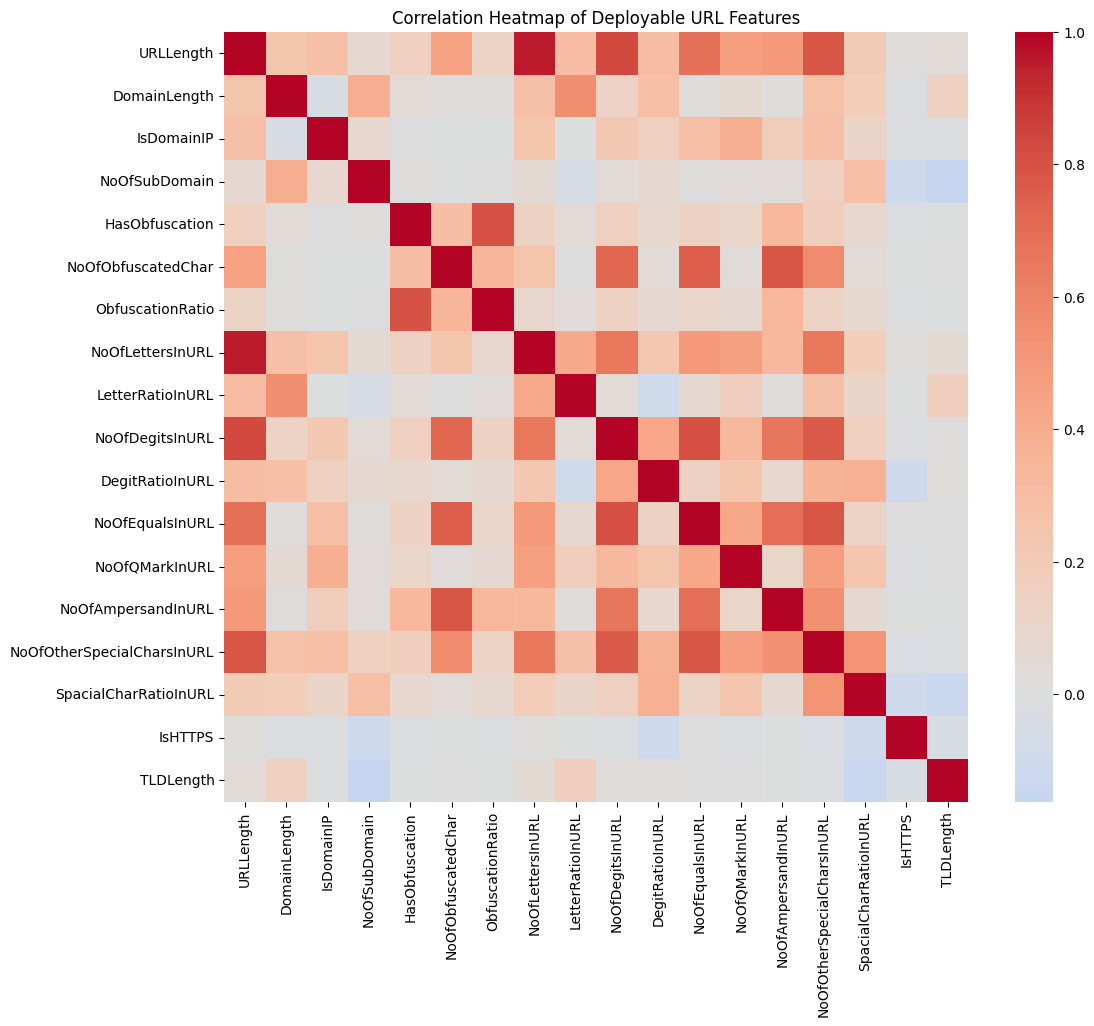

In [18]:
if 'df_url' in locals() and len(available_url_features) > 0:
    import seaborn as sns
    import matplotlib.pyplot as plt

    corr_matrix = df_url[available_url_features].corr()
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
    plt.title('Correlation Heatmap of Deployable URL Features')
    plt.show()


## 11. Scaling
- **Logistic Regression** benefits from scaled features so that features with large numerical ranges (like URLLength) do not disproportionately dominate the gradient updates.
- **Random Forest** relies on splitting nodes based on order/thresholds, so it is invariant to monotonic transformations and does not require scaling.
We prepare unscaled features for Random Forest, and we will apply a StandardScaler inside a Pipeline if we train a Logistic Regression model later.


## 12. Prepare X_url and y_url


In [19]:
if 'df_url' in locals() and len(available_url_features) > 0:
    X_url = df_url[available_url_features]
    y_url = df_url['label']


## 13. Train/test split
We split the data before any potential learned preprocessing (like scaling or imputation) to strictly prevent data leakage.


In [20]:
if 'df_url' in locals() and len(available_url_features) > 0:
    X_url_train, X_url_test, y_url_train, y_url_test = train_test_split(
        X_url, y_url, test_size=0.20, random_state=42, stratify=y_url
    )
    print(f'URL Train size: {X_url_train.shape[0]}, Test size: {X_url_test.shape[0]}')


URL Train size: 188636, Test size: 47159


## 14. Save the preprocessing decisions
Data and feature sets are ready in memory for the modeling phase.


In [21]:
# Ready for next stage


==================================================
GENERAL REQUIREMENTS
==================================================


## Preprocessing Decisions and Rationale

| Decision | Dataset | Reason |
|---|---|---|
| Dropped `Unnamed: 0`, `Date` | Email | Have no predictive value; temporal data risks model memorization. |
| Filled missing `Message` with `''` | Email | Preserves the `Subject` field which may contain strong signals. |
| Combined `Subject` and `Message` | Email | Provides a single, comprehensive text field for feature extraction. |
| Light text cleaning | Email | Avoids over-cleaning, retaining potential spam indicators like punctuation or aggressive casing. |
| Train/test split BEFORE TF-IDF | Email | Strictly avoids data leakage into the test set vocabulary and IDF scores. |
| Dropped `FILENAME` | URL | Merely a structural identifier with no ML value. |
| Excluded webpage-dependent features | URL | Ensures the model can classify URLs purely based on the string without dangerous/slow HTTP requests. |
| Maintained correlated features | URL | Tree-based models are robust to multicollinearity. |
| No SMOTE | Both | Datasets are already reasonably balanced. |
